# Mobile-FOG: Ekstraksi `DWPose-m` + `PatientLock-2Pass` & Preprocessing Scenario A / B / D + QC Pose
**Target Lingkungan:** Kaggle Notebook — **Accelerator: GPU T4 x2** (`2× NVIDIA T4`) & **Internet: ON**

Notebook ini padanan notebook ekstraksi YOLO tim (`parkinsonfp-biomed.ipynb`), dengan estimator **DWPose-m** (133 keypoint COCO-WholeBody):
1. **Isolasi pasien (PatientLock-2Pass) + ekstraksi pose paralel (`2× T4`)**: memakai bounding box pasien dari dataset Kaggle `ajikajadeh/mobile-fog-patient-bboxes`, sama dengan notebook ekstraksi YOLO tim. Per frame: *crop* mengikuti box pasien + *padding* 15%, area pengawas ditutup abu (inti pasien dipertahankan), detektor YOLOX-m di dalam crop, deteksi dengan IoU terbesar terhadap box pasien (≥ `MIN_CROP_IOU`), lalu **DWPose-m** (bukan RTMW) hanya pada box itu, dan koordinat di-remap ke frame asli. **Setiap frame (30 fps)** disimpan ke `01_extracted_poses_raw/dwpose_m/`.
2. **Preprocessing Scenario A / B / D**: kode **disalin persis** dari notebook ekstraksi YOLO tim (hanya nama folder `yolo26n_lb6_` → `dwpose_m_lb6_`), sehingga hasilnya bisa langsung dipakai notebook training 4 model tim dengan mengganti `DATA_DIR`.
3. **QC pose (hanya melapor, tidak mengubah data)**: metrik per trial (frame valid, confidence rendah, lonjakan, swap kiri-kanan, salah orang, kecocokan jumlah frame), plot sinyal, klip overlay 15 detik untuk dicek manual, dan lembar `qc_manual_review.csv`.

Notebook ini dihasilkan oleh skrip builder di repo (modul + unit test). Jangan edit sel kode di sini secara langsung, ubah di sumbernya lalu generate ulang.

In [1]:
# rtmlib mewajibkan paket 'onnxruntime' (CPU) yang bentrok dengan 'onnxruntime-gpu' -> pasang --no-deps
!pip uninstall -y -q onnxruntime
!pip install -q --no-deps rtmlib==0.0.16
!pip install -q onnxruntime-gpu==1.32.0 tqdm  # versi teruji di Kaggle (CUDA 13, torch cu130)

import os
import sys
import json
import time
import shutil
import subprocess
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch  # import torch dulu: memuat library CUDA/cuDNN yang juga dipakai onnxruntime-gpu
import onnxruntime as ort
if hasattr(ort, "preload_dlls"):
    ort.preload_dlls()

"""Notebook helpers: GPU provider check, dataset auto-detect, cross-session resume, ETA."""
import os
import shutil
from pathlib import Path

SKIP_WALK = {"videos", "imu_128hz", "labels_15hz", "labels_30hz"}


def require_cuda_provider(providers):
    if "CUDAExecutionProvider" not in providers:
        raise RuntimeError(
            f"onnxruntime tidak punya CUDAExecutionProvider (providers={providers}). "
            "Pastikan paket 'onnxruntime-gpu' yang terpasang (bukan versi CPU): "
            "!pip uninstall -y onnxruntime && !pip install onnxruntime-gpu, lalu restart kernel. "
            "Accelerator Kaggle juga harus 'GPU T4 x2'."
        )


def find_dataset_root(candidates):
    for cand in candidates:
        cand = Path(cand)
        if not cand.exists():
            continue
        for d, dirs, _ in os.walk(cand):
            p = Path(d)
            if (p / "train" / "videos").is_dir() and (p / "val" / "videos").is_dir():
                return p
            dirs[:] = sorted(x for x in dirs if x not in SKIP_WALK)
    raise FileNotFoundError(
        f"Folder dataset (berisi train/videos & val/videos) tidak ditemukan di: {[str(c) for c in candidates]}. "
        "Tambahkan dataset 'Train Val Test' sebagai Kaggle Input."
    )


def find_bbox_root(candidates):
    """Folder that contains patient_bboxes_npz/{train,test} (Kaggle dataset ajikajadeh/mobile-fog-patient-bboxes)."""
    for cand in candidates:
        cand = Path(cand)
        if not cand.exists():
            continue
        for d, dirs, _ in os.walk(cand):
            p = Path(d)
            if p.name == "patient_bboxes_npz" and (p / "train").is_dir() and (p / "test").is_dir():
                return p.parent
            dirs[:] = sorted(x for x in dirs if x not in SKIP_WALK)
    raise FileNotFoundError(
        f"Folder 'patient_bboxes_npz' tidak ditemukan di: {[str(c) for c in candidates]}. "
        "Tambahkan dataset Kaggle 'ajikajadeh/mobile-fog-patient-bboxes' ke Input notebook."
    )


def restore_previous_outputs(input_root, raw_dir):
    """Copy DWPose raw npz from an attached previous output into raw_dir (resume across sessions)."""
    input_root, raw_dir = Path(input_root), Path(raw_dir)
    if not input_root.exists():
        return 0
    n = 0
    for f in sorted(input_root.rglob("01_extracted_poses_raw/dwpose_m/*/*.npz")):
        if f.name.endswith(".tmp.npz"):
            continue
        dst = raw_dir / f.parent.name / f.name
        if dst.exists():
            continue
        dst.parent.mkdir(parents=True, exist_ok=True)
        tmp = dst.with_name(f"{dst.stem}.{os.getpid()}.tmp.npz")
        shutil.copy2(f, tmp)
        os.replace(tmp, dst)  # atomic: an interrupted copy never looks like a finished file
        n += 1
    return n


def eta_hours(ms_per_frame, total_frames, n_gpus):
    return ms_per_frame * total_frames / 1000.0 / 3600.0 / max(int(n_gpus), 1)


print(f"PyTorch     : {torch.__version__}")
print(f"onnxruntime : {ort.__version__} | providers: {ort.get_available_providers()}")
print(f"CUDA avail  : {torch.cuda.is_available()} | GPU count: {torch.cuda.device_count()}")
for i in range(torch.cuda.device_count()):
    props = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {props.name} ({props.total_memory / 1024**3:.1f} GB VRAM)")
require_cuda_provider(ort.get_available_providers())

PyTorch     : 2.11.0+cu130
onnxruntime : 1.32.0 | providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
CUDA avail  : True | GPU count: 2
  GPU 0: Tesla T4 (14.6 GB VRAM)
  GPU 1: Tesla T4 (14.6 GB VRAM)


In [2]:
# ==============================================================================
# PATH (auto-detect; bisa juga dijalankan lokal dari root repo)
# ==============================================================================
DATASET_ROOT = find_dataset_root([Path("/kaggle/input"), Path("dataset"), Path("Data/Train Val Test")])
# Dataset Kaggle 'ajikajadeh/mobile-fog-patient-bboxes' (berisi patient_bboxes_npz/{train,val,test}/)
if os.environ.get("MOBILEFOG_BBOX_ROOT"):
    BBOX_ROOT = Path(os.environ["MOBILEFOG_BBOX_ROOT"])
else:
    BBOX_ROOT = find_bbox_root([Path("/kaggle/input"), Path("Data")])
if os.environ.get("MOBILEFOG_OUTPUT_ROOT"):
    OUTPUT_ROOT = Path(os.environ["MOBILEFOG_OUTPUT_ROOT"])
elif Path("/kaggle/working").exists():
    OUTPUT_ROOT = Path("/kaggle/working/mobilefog_dwpose_patientlock")
else:
    OUTPUT_ROOT = Path("output/mobilefog_dwpose_patientlock")
RAW_POSE_DIR = OUTPUT_ROOT / "01_extracted_poses_raw" / "dwpose_m"
QC_DIR = OUTPUT_ROOT / "03_qc"

# ==============================================================================
# MODEL DWPose-m eksplisit (BUKAN kelas Wholebody rtmlib: semua mode bawaannya = RTMW)
# ==============================================================================
DET_URL = "https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/yolox_m_8xb8-300e_humanart-c2c7a14a.zip"
POSE_URL = "https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/rtmpose-m_simcc-ucoco_dw-ucoco_270e-256x192-c8b76419_20230728.zip"

# Bagian yang diekstraksi di sesi ini. Jika estimasi > 9 jam: mis. ["train"] dulu,
# lalu ["val", "test"] di sesi berikutnya (lampirkan output sesi sebelumnya sebagai Input).
RUN_SPLITS = ["train", "val", "test"]
MAX_FRAMES = None          # None = seluruh frame (hanya diubah untuk uji coba)
BENCHMARK_FRAMES = 300     # jumlah frame untuk mengukur kecepatan sebelum ekstraksi penuh

# ==============================================================================
# KONSTANTA PATIENTLOCK & PREPROCESSING (disalin persis dari notebook ekstraksi YOLO tim, cell 2)
# ==============================================================================
DET_CONF = 0.20                    # Sedikit lebih longgar di dalam crop pasien agar kaki tidak hilang

# Parameter PatientLock-2Pass Crop & Masking
CROP_PAD_RATIO = 0.15              # Padding 15% di sekitar bbox pasien agar engkel tidak terpotong
MASK_SUPERVISORS = True            # Tutup area pengawas (non_patient_flat) di tepi crop dengan abu netral
MIN_CROP_IOU = 0.20                # IoU minimum antara deteksi YOLO dalam crop vs bbox inti pasien

# Topologi LB6: 6 sendi tungkai bawah dari 17 COCO keypoints
LB6_INDICES = [11, 12, 13, 14, 15, 16]
LB6_NAMES = ["L_Hip", "R_Hip", "L_Knee", "R_Knee", "L_Ankle", "R_Ankle"]

CONF_VALID_THRES = 0.20
HAMPEL_WINDOW = 7
HAMPEL_SIGMA = 3.0
BUTTER_CUTOFF_HZ = 9.0

WINDOW_SEC = 2.0
STRIDE_SEC = 1.0
RANDOM_SEED = 42

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print(f"DATASET_ROOT : {DATASET_ROOT}")
print(f"BBOX_ROOT    : {BBOX_ROOT}")
print(f"OUTPUT_ROOT  : {OUTPUT_ROOT}")

DATASET_ROOT : /kaggle/input/datasets/melekbengi/parkinson/Train Val Test
BBOX_ROOT    : /kaggle/input/datasets/ajikajadeh/mobile-fog-patient-bboxes
OUTPUT_ROOT  : /kaggle/working/mobilefog_dwpose_patientlock


In [3]:
SPLITS = ["train", "val", "test"]
trial_records = []

for split in SPLITS:
    v_dir = DATASET_ROOT / split / "videos"
    l30_dir = DATASET_ROOT / split / "labels_30hz"
    l15_dir = DATASET_ROOT / split / "labels_15hz"
    bb_dir = BBOX_ROOT / "patient_bboxes_npz" / split

    videos = sorted(v_dir.glob("*.mp4"))
    for vp in videos:
        tid = vp.stem
        sid = tid.split("_")[0].replace("PDFE", "")
        l30 = l30_dir / f"{tid}.csv"
        l15 = l15_dir / f"{tid}.csv"
        bb_npz = bb_dir / f"{tid}.npz"
        assert l30.exists(), f"Missing 30Hz label: {l30}"
        assert l15.exists(), f"Missing 15Hz label: {l15}"
        assert bb_npz.exists(), f"Missing PatientLock bbox: {bb_npz}"
        trial_records.append({
            "split": split,
            "trial_id": tid,
            "subject_id": sid,
            "video_path": str(vp),
            "label30_path": str(l30),
            "label15_path": str(l15),
            "bbox_npz_path": str(bb_npz),
        })

df_manifest = pd.DataFrame(trial_records)
df_manifest.to_csv(OUTPUT_ROOT / "manifest_trials_local.csv", index=False)

print("Ringkasan Dataset (Video + Label 15/30Hz + PatientLock BBox):")
print(df_manifest.groupby("split").agg(trials=("trial_id", "count"), subjects=("subject_id", "nunique")))
assert len(df_manifest) == 71, f"Peringatan: ditemukan {len(df_manifest)} video (harapan 71)."
print("Audit 71 video, label 15Hz/30Hz, & patient_bboxes_npz: LENGKAP.")


Ringkasan Dataset (Video + Label 15/30Hz + PatientLock BBox):
       trials  subjects
split                  
test       14         7
train      47        23
val        10         5
Audit 71 video, label 15Hz/30Hz, & patient_bboxes_npz: LENGKAP.


In [4]:
# ==============================================================================
# LANJUTKAN DARI SESI SEBELUMNYA + SKEMA SENDI
# ==============================================================================
RAW_POSE_DIR.mkdir(parents=True, exist_ok=True)
n_restored = restore_previous_outputs(Path("/kaggle/input"), RAW_POSE_DIR)
n_done = len(list(RAW_POSE_DIR.glob("*/*.npz"))) - len(list(RAW_POSE_DIR.glob("*/*.tmp.npz")))
print(f"Dipulihkan dari Input: {n_restored} file | total trial sudah diekstraksi: {n_done}/{len(df_manifest)}")

joint_schema = {
    "estimator": "DWPose-m (rtmpose-m ucoco dw, 256x192) + YOLOX-m HumanArt detector",
    "det_url": DET_URL,
    "pose_url": POSE_URL,
    "num_keypoints": 133,
    "layout": "COCO-WholeBody: 0-16 body (COCO-17), 17-22 feet, 23-90 face, 91-132 hands",
    "coords": "pixel (resolusi asli video), kolom ke-3 = skor keypoint",
    "lb6_indices": LB6_INDICES,
    "lb6_names": LB6_NAMES,
    "feet_indices": {"L_BigToe": 17, "L_SmallToe": 18, "L_Heel": 19, "R_BigToe": 20, "R_SmallToe": 21, "R_Heel": 22},
    "patient_lock": "PatientLock-2Pass (ajikajadeh/mobile-fog-patient-bboxes)",
    "crop_pad_ratio": CROP_PAD_RATIO,
    "mask_supervisors": MASK_SUPERVISORS,
    "min_crop_iou": MIN_CROP_IOU,
    "det_conf": DET_CONF,
    "boxes": "box pasien dari dataset bbox (piksel); kps nol + valid=False jika tidak ada box/match",
}
with open(RAW_POSE_DIR.parent / "joint_schema.json", "w") as f:
    json.dump(joint_schema, f, indent=2)

Dipulihkan dari Input: 0 file | total trial sudah diekstraksi: 0/71


In [5]:
# ==============================================================================
# TULIS SKRIP WORKER EKSTRAKSI (dijalankan 1 proses per GPU, pola notebook ekstraksi YOLO tim)
# ==============================================================================
WORKER_SRC = r'''"""PatientLock-2Pass helpers for the DWPose worker.

`_box_iou_one_to_many` and `_crop_and_mask_patient` are VERBATIM copies of the team YOLO extraction
notebook's worker (parkinsonfp-biomed.ipynb, cell 4); a test enforces it. Do not edit them here.
"""
import numpy as np


def _box_iou_one_to_many(target_box: np.ndarray, boxes: np.ndarray) -> np.ndarray:
    ix1 = np.maximum(target_box[0], boxes[:, 0])
    iy1 = np.maximum(target_box[1], boxes[:, 1])
    ix2 = np.minimum(target_box[2], boxes[:, 2])
    iy2 = np.minimum(target_box[3], boxes[:, 3])
    inter = np.maximum(0.0, ix2 - ix1) * np.maximum(0.0, iy2 - iy1)
    area_t = max(0.0, (target_box[2] - target_box[0]) * (target_box[3] - target_box[1]))
    area_b = np.maximum(0.0, (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]))
    return inter / np.maximum(area_t + area_b - inter, 1e-6)


def _crop_and_mask_patient(
    frame: np.ndarray,
    pbox_norm: np.ndarray,
    sup_boxes_norm: np.ndarray,
    pad_ratio: float,
    mask_supervisors: bool,
):
    H, W = frame.shape[:2]
    px1 = float(np.clip(pbox_norm[0] * W, 0, W - 1))
    py1 = float(np.clip(pbox_norm[1] * H, 0, H - 1))
    px2 = float(np.clip(pbox_norm[2] * W, px1 + 1, W))
    py2 = float(np.clip(pbox_norm[3] * H, py1 + 1, H))

    bw = px2 - px1
    bh = py2 - py1
    cx1 = int(max(0, np.floor(px1 - pad_ratio * bw)))
    cy1 = int(max(0, np.floor(py1 - pad_ratio * bh)))
    cx2 = int(min(W, np.ceil(px2 + pad_ratio * bw)))
    cy2 = int(min(H, np.ceil(py2 + pad_ratio * bh)))

    crop = frame[cy1:cy2, cx1:cx2].copy()
    ch, cw = crop.shape[:2]
    core_in_crop = np.array([px1 - cx1, py1 - cy1, px2 - cx1, py2 - cy1], dtype=np.float32)

    if mask_supervisors and len(sup_boxes_norm) > 0:
        # Simpan area inti pasien dulu agar tidak ikut tertutup jika bbox pengawas sedikit bersinggungan
        ix1, iy1 = int(max(0, np.floor(core_in_crop[0]))), int(max(0, np.floor(core_in_crop[1])))
        ix2, iy2 = int(min(cw, np.ceil(core_in_crop[2]))), int(min(ch, np.ceil(core_in_crop[3])))
        patient_patch = crop[iy1:iy2, ix1:ix2].copy()

        for sb in sup_boxes_norm:
            sx1 = int(np.clip(np.floor(float(sb[0]) * W) - cx1, 0, cw))
            sy1 = int(np.clip(np.floor(float(sb[1]) * H) - cy1, 0, ch))
            sx2 = int(np.clip(np.ceil(float(sb[2]) * W) - cx1, 0, cw))
            sy2 = int(np.clip(np.ceil(float(sb[3]) * H) - cy1, 0, ch))
            if sx2 > sx1 and sy2 > sy1:
                crop[sy1:sy2, sx1:sx2] = (114, 114, 114)

        crop[iy1:iy2, ix1:ix2] = patient_patch

    pbox_px = np.array([px1, py1, px2, py2], dtype=np.float32)
    return crop, (cx1, cy1), core_in_crop, pbox_px


def pick_box_in_crop(boxes, core_in_crop, min_iou):
    """Index of the detection (crop coords) with the largest IoU vs the patient core box, or None
    if there is none / it is below min_iou (team rule from `_pick_pose_in_crop`)."""
    boxes = np.asarray(boxes, np.float32).reshape(-1, 4)
    if len(boxes) == 0:
        return None
    ious = _box_iou_one_to_many(np.asarray(core_in_crop, np.float32), boxes)
    idx = int(np.argmax(ious))
    return idx if ious[idx] >= min_iou else None


def frame_supervisor_boxes(non_patient_flat, non_patient_offsets, f):
    """Supervisor boxes (normalised xyxy) of frame f from the CSR layout of the bbox dataset."""
    s0, s1 = int(non_patient_offsets[f]), int(non_patient_offsets[f + 1])
    if s1 <= s0:
        return np.empty((0, 4), dtype=np.float32)
    return np.asarray(non_patient_flat[s0:s1, :4], dtype=np.float32)


"""DWPose-m + PatientLock-2Pass extraction worker (one process per GPU).

Mirrors the team YOLO extraction notebook's `_yolo_patientlock_worker.py`, with YOLO26n-pose replaced by
rtmlib YOLOX-m (detector, run inside the patient crop) + DWPose-m (top-down pose on the matched box only).

Run as:  python _dwpose_extract_worker.py job.json
job = {"gpu_label": int,
       "cfg": {"out_dir", "det_url", "pose_url", "max_frames", "device", "det_conf",
               "crop_pad_ratio", "mask_supervisors", "min_crop_iou"},
       "tasks": [{"split", "trial_id", "video_path", "bbox_npz_path"}, ...]}
"""
import json
import os
import sys
import time
from pathlib import Path

import cv2
import numpy as np


DET_INPUT_SIZE = (640, 640)
POSE_INPUT_SIZE = (192, 256)
SELECTOR = "patientlock-2pass"


def build_models(det_url, pose_url, device, det_conf=0.20):
    """det_fn(img) -> (boxes (N,4) xyxy, scores (N,)) with the team's DET_CONF; pose_fn(img, boxes) -> (kps, scores).
    rtmlib's YOLOX hard-codes score > 0.3 for this NMS-in-graph model, so scores are read from the ONNX output."""
    if str(device).startswith("cuda"):
        # Same as the notebook's main process: torch loads the pip CUDA/cuDNN libs, preload_dlls
        # lets onnxruntime-gpu find them. Without this a worker subprocess can fall back to CPU.
        try:
            import torch  # noqa: F401
        except ImportError:
            pass
        import onnxruntime as ort
        if hasattr(ort, "preload_dlls"):
            ort.preload_dlls()
    from rtmlib import RTMPose, YOLOX

    det = YOLOX(det_url, model_input_size=DET_INPUT_SIZE, backend="onnxruntime", device=device)
    pose = RTMPose(pose_url, model_input_size=POSE_INPUT_SIZE, to_openpose=False,
                   backend="onnxruntime", device=device)

    def det_fn(img):
        x, ratio = det.preprocess(img)
        out = np.asarray(det.inference(x)[0])
        if out.shape[-1] != 5:
            raise RuntimeError(f"Unexpected YOLOX output shape {out.shape} (expected NMS-in-graph, last dim 5)")
        boxes, scores = out[0, :, :4] / ratio, out[0, :, 4]
        keep = scores > det_conf
        return boxes[keep].astype(np.float32), scores[keep].astype(np.float32)

    def pose_fn(img, boxes):
        return pose(img, bboxes=boxes)

    det_fn.providers = list(det.session.get_providers())
    pose_fn.providers = list(pose.session.get_providers())
    return det_fn, pose_fn


def check_providers(providers, device):
    """onnxruntime silently falls back to CPU when CUDA/cuDNN libs are missing; fail loudly instead."""
    if str(device).startswith("cuda") and "CUDAExecutionProvider" not in providers:
        raise RuntimeError(f"Model DWPose jatuh ke CPU (providers={providers}) padahal device={device}. "
                           "Cek instalasi onnxruntime-gpu / CUDA / cuDNN.")


def extract_video(video_path, bbox_npz_path, det_fn, pose_fn, crop_pad_ratio, mask_supervisors, min_crop_iou,
                  max_frames=None):
    bb = np.load(bbox_npz_path)
    pboxes_norm, is_det = bb["patient_box_norm"], bb["is_detected"]
    non_pat_flat, non_pat_off = bb["non_patient_flat"], bb["non_patient_offsets"]
    n_bb = len(pboxes_norm)

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {video_path}")
    fps = float(cap.get(cv2.CAP_PROP_FPS) or 29.98)
    W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    n_video = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    all_kps, all_boxes, all_valid, all_n = [], [], [], []
    t0 = time.perf_counter()
    f = 0
    while max_frames is None or f < max_frames:
        ok, frame = cap.read()
        if not ok:
            break
        kp, box, valid, n = np.zeros((133, 3), np.float32), np.zeros(4, np.float32), False, 0
        if f < n_bb and bool(is_det[f]):
            sup_b = frame_supervisor_boxes(non_pat_flat, non_pat_off, f)
            crop, off_xy, core_box, pbox_px = _crop_and_mask_patient(
                frame, pboxes_norm[f], sup_b, crop_pad_ratio, mask_supervisors)
            box = pbox_px.astype(np.float32)
            boxes, _scores = det_fn(crop)
            boxes = np.asarray(boxes, np.float32).reshape(-1, 4)
            n = len(boxes)
            idx = pick_box_in_crop(boxes, core_box, min_crop_iou)
            if idx is not None:
                kps, scores = pose_fn(crop, boxes[idx:idx + 1])
                kp = np.concatenate([np.asarray(kps[0], np.float32), np.asarray(scores[0], np.float32)[:, None]], axis=-1)
                kp[:, 0] += float(off_xy[0])
                kp[:, 1] += float(off_xy[1])
                valid = True
        all_kps.append(kp)
        all_boxes.append(box)
        all_valid.append(valid)
        all_n.append(n)
        f += 1
    cap.release()

    n_frames = max(len(all_kps), 1)
    return {
        "kps": np.asarray(all_kps, np.float32).reshape(-1, 133, 3),
        "boxes": np.asarray(all_boxes, np.float32).reshape(-1, 4),
        "valid": np.asarray(all_valid, bool),
        "fps": np.float32(fps),
        "W": np.int32(W),
        "H": np.int32(H),
        "n_persons": np.asarray(all_n, np.int16),
        "ms_per_frame": np.float32(1000.0 * (time.perf_counter() - t0) / n_frames),
        "max_frames": np.int32(-1 if max_frames is None else max_frames),
        "n_video": np.int32(n_video),
        "selector": np.array(SELECTOR),
    }


def is_complete(path):
    """A raw npz counts as done only if it loads, was made with PatientLock (selector marker), came from a
    full run (max_frames=-1), and covers the whole video (1 frame of decoder slack allowed)."""
    try:
        with np.load(path) as z:
            if str(z["selector"]) != SELECTOR or int(z["max_frames"]) != -1:
                return False
            return len(z["valid"]) >= int(z["n_video"]) - 1 and z["kps"].shape[0] == len(z["valid"])
    except Exception:
        return False


def save_npz_atomic(path, arrays):
    path = Path(path)
    # pid in the temp name: two workers (e.g. after a kernel interrupt + re-run) never share a temp file
    tmp = path.with_name(f"{path.stem}.{os.getpid()}.tmp.npz")
    np.savez_compressed(tmp, **arrays)
    os.replace(tmp, path)


def main(job_path):
    job = json.loads(Path(job_path).read_text(encoding="utf-8"))
    gpu_label, cfg = job["gpu_label"], job["cfg"]
    out_dir = Path(cfg["out_dir"])
    pending = [t for t in job["tasks"] if not is_complete(out_dir / t["split"] / f"{t['trial_id']}.npz")]
    if not pending:
        print(f"[GPU {gpu_label}] Semua trial sudah diekstraksi, tidak ada yang dikerjakan.", flush=True)
        return

    device = cfg.get("device", "cuda")
    det_fn, pose_fn = build_models(cfg["det_url"], cfg["pose_url"], device, cfg.get("det_conf", 0.20))
    for fn in (det_fn, pose_fn):
        if hasattr(fn, "providers"):
            check_providers(fn.providers, device)
    for item in pending:
        save_path = out_dir / item["split"] / f"{item['trial_id']}.npz"
        save_path.parent.mkdir(parents=True, exist_ok=True)
        res = extract_video(item["video_path"], item["bbox_npz_path"], det_fn, pose_fn,
                            cfg["crop_pad_ratio"], cfg["mask_supervisors"], cfg["min_crop_iou"],
                            cfg.get("max_frames"))
        save_npz_atomic(save_path, res)
        print(f"[GPU {gpu_label}] Selesai {item['split']}/{item['trial_id']}: {len(res['valid'])} frame | "
              f"valid={res['valid'].mean() * 100:.2f}% | {float(res['ms_per_frame']):.1f} ms/frame", flush=True)


if __name__ == "__main__":
    main(sys.argv[1])
'''
WORKER_PATH = OUTPUT_ROOT / "_dwpose_extract_worker.py"
WORKER_PATH.write_text(WORKER_SRC, encoding="utf-8")
print(f"Worker ditulis ke {WORKER_PATH}")

Worker ditulis ke /kaggle/working/mobilefog_dwpose_patientlock/_dwpose_extract_worker.py


In [6]:
# ==============================================================================
# UJI KECEPATAN (sekaligus mengunduh model sekali sebelum worker paralel berjalan)
# ==============================================================================
wk = {"__name__": "dwpose_worker"}
exec(compile(WORKER_SRC, str(WORKER_PATH), "exec"), wk)

pending = [r for r in df_manifest.itertuples()
           if r.split in RUN_SPLITS and not wk["is_complete"](RAW_POSE_DIR / r.split / f"{r.trial_id}.npz")]
n_gpus = max(1, torch.cuda.device_count())
if pending:
    det_fn, pose_fn = wk["build_models"](DET_URL, POSE_URL, "cuda", DET_CONF)
    wk["check_providers"](det_fn.providers, "cuda")
    wk["check_providers"](pose_fn.providers, "cuda")
    bench = wk["extract_video"](pending[0].video_path, pending[0].bbox_npz_path, det_fn, pose_fn,
                                CROP_PAD_RATIO, MASK_SUPERVISORS, MIN_CROP_IOU, max_frames=BENCHMARK_FRAMES)
    ms = float(bench["ms_per_frame"])
    total_frames = sum(int(cv2.VideoCapture(r.video_path).get(cv2.CAP_PROP_FRAME_COUNT)) for r in pending)
    eta = eta_hours(ms, total_frames, n_gpus)
    print(f"Benchmark {pending[0].trial_id}: {ms:.1f} ms/frame | valid={bench['valid'].mean()*100:.1f}% | "
          f"deteksi dalam crop/frame={bench['n_persons'].mean():.2f}")
    print(f"{len(pending)} trial tersisa, {total_frames} frame, {n_gpus} GPU -> estimasi {eta:.2f} jam")
    if eta > 9:
        print("PERINGATAN: estimasi > 9 jam (batas sesi Kaggle ~12 jam). Ubah RUN_SPLITS di sel konfigurasi "
              "(mis. ['train'] dulu), jalankan ulang, lalu lanjutkan split lain di sesi berikutnya.")
    del det_fn, pose_fn, bench
else:
    print("Semua trial pada RUN_SPLITS sudah diekstraksi.")

Downloading: "https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/yolox_m_8xb8-300e_humanart-c2c7a14a.zip" to /root/.cache/rtmlib/hub/checkpoints/yolox_m_8xb8-300e_humanart-c2c7a14a.zip
100%|██████████| 89.9M/89.9M [00:05<00:00, 16.2MB/s]
2026-11-23 16:51:53.569729749 [W:onnxruntime:, session_state.cc:1618 VerifyEachNodeIsAssignedToAnEp] Some nodes were not assigned to the preferred execution providers which may or may not have an negative impact on performance. e.g. ORT explicitly assigns shape related ops to CPU to improve perf.
2026-11-23 16:51:53.569791771 [W:onnxruntime:, session_state.cc:1620 VerifyEachNodeIsAssignedToAnEp] Rerunning with verbose output on a non-minimal build will show node assignments.


load /root/.cache/rtmlib/hub/checkpoints/yolox_m_8xb8-300e_humanart-c2c7a14a.onnx with onnxruntime backend


Downloading: "https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/rtmpose-m_simcc-ucoco_dw-ucoco_270e-256x192-c8b76419_20230728.zip" to /root/.cache/rtmlib/hub/checkpoints/rtmpose-m_simcc-ucoco_dw-ucoco_270e-256x192-c8b76419_20230728.zip
100%|██████████| 63.9M/63.9M [00:04<00:00, 15.8MB/s]
2026-11-23 16:52:00.114494001 [W:onnxruntime:, session_state.cc:1618 VerifyEachNodeIsAssignedToAnEp] Some nodes were not assigned to the preferred execution providers which may or may not have an negative impact on performance. e.g. ORT explicitly assigns shape related ops to CPU to improve perf.
2026-11-23 16:52:00.114523356 [W:onnxruntime:, session_state.cc:1620 VerifyEachNodeIsAssignedToAnEp] Rerunning with verbose output on a non-minimal build will show node assignments.


load /root/.cache/rtmlib/hub/checkpoints/rtmpose-m_simcc-ucoco_dw-ucoco_270e-256x192-c8b76419_20230728.onnx with onnxruntime backend
Benchmark PDFE02_1: 86.8 ms/frame | valid=100.0% | deteksi dalam crop/frame=1.00
71 trial tersisa, 255890 frame, 2 GPU -> estimasi 3.08 jam


In [7]:
# ==============================================================================
# TAHAP 1: EKSTRAKSI DWPose-m + PATIENTLOCK-2PASS PARALEL PADA 2x T4 GPU (SUBPROCESS ISOLATED)
# ==============================================================================
tasks_list = [{"split": r.split, "trial_id": r.trial_id, "video_path": r.video_path, "bbox_npz_path": r.bbox_npz_path}
              for r in df_manifest.itertuples() if r.split in RUN_SPLITS]
cfg_dict = {"out_dir": str(RAW_POSE_DIR), "det_url": DET_URL, "pose_url": POSE_URL,
            "max_frames": MAX_FRAMES, "device": "cuda", "det_conf": DET_CONF,
            "crop_pad_ratio": CROP_PAD_RATIO, "mask_supervisors": MASK_SUPERVISORS, "min_crop_iou": MIN_CROP_IOU}

t0 = time.time()
shards = [tasks_list[i::n_gpus] for i in range(n_gpus)]
procs = []
try:
    for gid in range(n_gpus):
        job_file = OUTPUT_ROOT / f"_dwpose_job_gpu{gid}.json"
        job_file.write_text(json.dumps({"gpu_label": gid, "cfg": cfg_dict, "tasks": shards[gid]}), encoding="utf-8")
        env = os.environ.copy()
        if torch.cuda.is_available():
            env["CUDA_VISIBLE_DEVICES"] = str(gid)
        p = subprocess.Popen([sys.executable, str(WORKER_PATH), str(job_file)], env=env)
        procs.append((gid, p))
    rcs = {gid: p.wait() for gid, p in procs}   # tunggu SEMUA worker
finally:
    for gid, p in procs:                         # kernel di-interrupt / error -> jangan tinggalkan worker hidup
        if p.poll() is None:
            p.terminate()
assert all(rc == 0 for rc in rcs.values()), f"Worker gagal: {rcs}"
print(f"Ekstraksi {len(tasks_list)} video selesai dalam {time.time() - t0:.1f} detik.")

2026-11-23 16:53:07.699124069 [W:onnxruntime:, session_state.cc:1618 VerifyEachNodeIsAssignedToAnEp] Some nodes were not assigned to the preferred execution providers which may or may not have an negative impact on performance. e.g. ORT explicitly assigns shape related ops to CPU to improve perf.
2026-11-23 16:53:07.699158869 [W:onnxruntime:, session_state.cc:1620 VerifyEachNodeIsAssignedToAnEp] Rerunning with verbose output on a non-minimal build will show node assignments.
2026-11-23 16:53:07.739719757 [W:onnxruntime:, session_state.cc:1618 VerifyEachNodeIsAssignedToAnEp] Some nodes were not assigned to the preferred execution providers which may or may not have an negative impact on performance. e.g. ORT explicitly assigns shape related ops to CPU to improve perf.
2026-11-23 16:53:07.739779510 [W:onnxruntime:, session_state.cc:1620 VerifyEachNodeIsAssignedToAnEp] Rerunning with verbose output on a non-minimal build will show node assignments.
2026-11-23 16:53:07.842797535 [W:onnxrun

load /root/.cache/rtmlib/hub/checkpoints/yolox_m_8xb8-300e_humanart-c2c7a14a.onnx with onnxruntime backend
load /root/.cache/rtmlib/hub/checkpoints/rtmpose-m_simcc-ucoco_dw-ucoco_270e-256x192-c8b76419_20230728.onnx with onnxruntime backend
[GPU 1] Selesai train/PDFE03_1: 3630 frame | valid=100.00% | 68.0 ms/frame
load /root/.cache/rtmlib/hub/checkpoints/yolox_m_8xb8-300e_humanart-c2c7a14a.onnx with onnxruntime backend
load /root/.cache/rtmlib/hub/checkpoints/rtmpose-m_simcc-ucoco_dw-ucoco_270e-256x192-c8b76419_20230728.onnx with onnxruntime backend
[GPU 0] Selesai train/PDFE02_1: 3688 frame | valid=100.00% | 69.5 ms/frame
[GPU 1] Selesai train/PDFE03_3: 3632 frame | valid=100.00% | 68.5 ms/frame
[GPU 0] Selesai train/PDFE03_2: 3635 frame | valid=100.00% | 68.5 ms/frame
[GPU 0] Selesai train/PDFE04_1: 3390 frame | valid=100.00% | 68.9 ms/frame
[GPU 1] Selesai train/PDFE05_1: 3610 frame | valid=100.00% | 68.9 ms/frame
[GPU 0] Selesai train/PDFE05_2: 3610 frame | valid=100.00% | 69.1 ms/f

In [8]:
# Preprocessing butuh SEMUA 71 trial LENGKAP (scaler di-fit pada seluruh train).
# File hasil uji coba MAX_FRAMES / terpotong / rusak / tanpa PatientLock tidak dihitung selesai.
missing = [f"{r.split}/{r.trial_id}" for r in df_manifest.itertuples()
           if not wk["is_complete"](RAW_POSE_DIR / r.split / f"{r.trial_id}.npz")]
assert not missing, (f"{len(missing)} trial belum diekstraksi lengkap (mis. {missing[:3]}). Pastikan MAX_FRAMES = None, "
                     "ubah RUN_SPLITS ke split yang tersisa, lalu jalankan ulang notebook "
                     "(lampirkan output sesi sebelumnya sebagai Input).")
print("Semua 71 trial sudah diekstraksi. Lanjut ke preprocessing (kode notebook YOLO tim).")

Semua 71 trial sudah diekstraksi. Lanjut ke preprocessing (kode notebook YOLO tim).


## Preprocessing Scenario A / B / D (kode notebook YOLO tim, disalin persis)
Tiga sel berikut diambil otomatis dari `parkinsonfp-biomed.ipynb` (versi PatientLock). Perubahan hanya:
`yolo26n_lb6_` → `dwpose_m_lb6_`, nama folder output, dan satu komentar. Jika menemukan bug di sini,
laporkan ke tim agar diperbaiki untuk semua estimator, jangan diubah sepihak.

In [9]:
# ==============================================================================
# TAHAP 2: FUNGSI PREPROCESSING SCENARIO A & SCENARIO B (LB6)
# ==============================================================================
from scipy.signal import butter, sosfiltfilt


def interpolate_low_conf(kps_lb6: np.ndarray, conf_thres: float = 0.20) -> np.ndarray:
    """Interpolasi linear koordinat (x, y) jika confidence < conf_thres."""
    out = kps_lb6.copy()
    T, V, _ = out.shape
    t_idx = np.arange(T)
    for v in range(V):
        good = out[:, v, 2] >= conf_thres
        if good.sum() == 0:
            out[:, v, :2] = 0.0
        elif good.sum() < T:
            for c in (0, 1):
                out[:, v, c] = np.interp(t_idx, t_idx[good], out[good, v, c])
    return out


def hampel_filter_1d(sig: np.ndarray, window: int = 7, n_sigma: float = 3.0) -> np.ndarray:
    """Hampel rolling-median filter untuk membersihkan lonjakan outlier pose."""
    s = pd.Series(sig, dtype=np.float64)
    med = s.rolling(window=window, center=True, min_periods=1).median()
    mad = (s - med).abs().rolling(window=window, center=True, min_periods=1).median()
    thresh = n_sigma * 1.4826 * mad
    out = s.copy()
    outlier = (s - med).abs() > thresh
    out[outlier] = med[outlier]
    return out.to_numpy(dtype=np.float32)


def butter_lowpass(sig: np.ndarray, fs: float, cutoff: float = 9.0, order: int = 4) -> np.ndarray:
    """Butterworth zero-phase low-pass filter (dipakai pada 30 Hz, cutoff < Nyquist 15 Hz)."""
    if cutoff >= 0.49 * fs or len(sig) < 18:
        return sig.astype(np.float32)
    sos = butter(order, cutoff, btype="low", fs=fs, output="sos")
    return sosfiltfilt(sos, sig).astype(np.float32)


def normalize_lb6(kps_lb6: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Pusatkan ke median pelvis & skalakan dengan median panjang kaki per trial."""
    # Indeks LB6: 0:L_Hip, 1:R_Hip, 2:L_Knee, 3:R_Knee, 4:L_Ankle, 5:R_Ankle
    pelvis = 0.5 * (kps_lb6[:, 0, :2] + kps_lb6[:, 1, :2])
    pelvis_center = np.median(pelvis, axis=0, keepdims=True)  # (1, 2)

    leg_l = (
        np.linalg.norm(kps_lb6[:, 0, :2] - kps_lb6[:, 2, :2], axis=-1)
        + np.linalg.norm(kps_lb6[:, 2, :2] - kps_lb6[:, 4, :2], axis=-1)
    )
    leg_r = (
        np.linalg.norm(kps_lb6[:, 1, :2] - kps_lb6[:, 3, :2], axis=-1)
        + np.linalg.norm(kps_lb6[:, 3, :2] - kps_lb6[:, 5, :2], axis=-1)
    )
    scale = float(np.median(0.5 * (leg_l + leg_r)))
    scale = max(scale, 1e-4)

    xy_norm = (kps_lb6[:, :, :2] - pelvis_center[:, None, :]) / scale
    conf = kps_lb6[:, :, 2:3]

    # Vektor tulang (bone_x, bone_y): Hip->pelvis(0), Knee->Hip, Ankle->Knee
    parent = [None, None, 0, 1, 2, 3]
    bones = np.zeros_like(xy_norm)
    for v, p in enumerate(parent):
        if p is not None:
            bones[:, v, :] = xy_norm[:, v, :] - xy_norm[:, p, :]
    return xy_norm.astype(np.float32), conf.astype(np.float32), bones.astype(np.float32)


def build_scenario_a_and_b(kps_17: np.ndarray, fs: float) -> tuple[np.ndarray, np.ndarray]:
    """Bangun Scenario A (T, 6, 7) dan Scenario B (T, 6, 9) untuk satu trial."""
    kps_lb6 = kps_17[:, LB6_INDICES, :].copy()
    kps_interp = interpolate_low_conf(kps_lb6, CONF_VALID_THRES)

    # --- Scenario A: [x, y, conf, dx, dy, bone_x, bone_y] ---
    xy_a, conf_a, bones_a = normalize_lb6(kps_interp)
    dx_a = np.gradient(xy_a[:, :, 0], axis=0)[:, :, None]
    dy_a = np.gradient(xy_a[:, :, 1], axis=0)[:, :, None]
    scen_a = np.concatenate([xy_a, conf_a, dx_a, dy_a, bones_a], axis=-1).astype(np.float32)

    # --- Scenario B: Hampel + Butterworth 9 Hz (pada 30 Hz) + accel ---
    kps_den = kps_interp.copy()
    for v in range(6):
        for c in (0, 1):
            sig = hampel_filter_1d(kps_den[:, v, c], window=HAMPEL_WINDOW, n_sigma=HAMPEL_SIGMA)
            if fs >= 25.0:
                sig = butter_lowpass(sig, fs=fs, cutoff=BUTTER_CUTOFF_HZ, order=4)
            kps_den[:, v, c] = sig

    xy_b, conf_b, bones_b = normalize_lb6(kps_den)
    dx_b = np.gradient(xy_b[:, :, 0], axis=0)[:, :, None]
    dy_b = np.gradient(xy_b[:, :, 1], axis=0)[:, :, None]
    ddx_b = np.gradient(dx_b[:, :, 0], axis=0)[:, :, None]
    ddy_b = np.gradient(dy_b[:, :, 0], axis=0)[:, :, None]
    scen_b = np.concatenate([xy_b, conf_b, dx_b, dy_b, ddx_b, ddy_b, bones_b], axis=-1).astype(np.float32)

    return scen_a, scen_b


In [10]:
# ==============================================================================
# TAHAP 3: SIMPAN SCENARIO A, B, DAN D (WINDOWED 15 HZ & 30 HZ)
# ==============================================================================
SCEN_DIR = OUTPUT_ROOT / "02_processed_scenarios"


def process_frequency(target_hz: int):
    assert target_hz in (15, 30)
    step = 2 if target_hz == 15 else 1
    win_len = int(round(WINDOW_SEC * target_hz))     # 30 @ 15Hz | 60 @ 30Hz
    stride_len = int(round(STRIDE_SEC * target_hz))  # 15 @ 15Hz | 30 @ 30Hz

    for scen_name in ["A_baseline_norm", "B_denoised_hampel_accel"]:
        (SCEN_DIR / scen_name / f"dwpose_m_lb6_{target_hz}hz").mkdir(parents=True, exist_ok=True)

    # Kumpulkan window Scenario D (dari fitur Scenario B sebagai default unggulan, dan A juga)
    for src_scen in ["A_baseline_norm", "B_denoised_hampel_accel"]:
        d_root = SCEN_DIR / "D_windowed_stgcn_cls" / f"from_{src_scen}_{target_hz}hz"
        d_root.mkdir(parents=True, exist_ok=True)

        split_buffers = {sp: {"X": [], "y_any": [], "y_maj": [], "y_ge25": [], "y_ratio": [], "trial_id": [], "subject_id": []} for sp in SPLITS}

        for row in df_manifest.itertuples():
            raw_npz = np.load(RAW_POSE_DIR / row.split / f"{row.trial_id}.npz")
            kps_all = raw_npz["kps"]  # (T30, 17, 3)

            lbl_path = row.label15_path if target_hz == 15 else row.label30_path
            df_lbl = pd.read_csv(lbl_path)

            kps_hz = kps_all[::step]
            n_frames = min(len(kps_hz), len(df_lbl))
            kps_hz = kps_hz[:n_frames]
            df_lbl = df_lbl.iloc[:n_frames].reset_index(drop=True)

            if src_scen == "A_baseline_norm":
                feat, _ = build_scenario_a_and_b(kps_hz, fs=float(target_hz))
                scen_save = SCEN_DIR / "A_baseline_norm" / f"dwpose_m_lb6_{target_hz}hz" / row.split
            else:
                _, feat = build_scenario_a_and_b(kps_hz, fs=float(target_hz))
                scen_save = SCEN_DIR / "B_denoised_hampel_accel" / f"dwpose_m_lb6_{target_hz}hz" / row.split

            scen_save.mkdir(parents=True, exist_ok=True)
            np.savez_compressed(
                scen_save / f"{row.trial_id}.npz",
                X=feat,
                y_fog=df_lbl["y_fog"].to_numpy(dtype=np.int64),
                inside_imu_mask=df_lbl["inside_imu_mask"].to_numpy(dtype=np.int64),
            )

            # Potong sliding window HANYA di frame dengan inside_imu_mask == 1
            mask = df_lbl["inside_imu_mask"].to_numpy(dtype=np.int64)
            y_seq = df_lbl["y_fog"].to_numpy(dtype=np.int64)

            for s_idx in range(0, n_frames - win_len + 1, stride_len):
                e_idx = s_idx + win_len
                if np.any(mask[s_idx:e_idx] == 0):
                    continue
                w_feat = feat[s_idx:e_idx]                # (T_win, 6, C)
                w_tensor = np.transpose(w_feat, (2, 0, 1)) # (C, T_win, 6) untuk ST-GCN / Mamba
                fog_ratio = float(np.mean(y_seq[s_idx:e_idx]))

                buf = split_buffers[row.split]
                buf["X"].append(w_tensor)
                buf["y_any"].append(int(fog_ratio > 0.0))
                buf["y_maj"].append(int(fog_ratio >= 0.5))
                buf["y_ge25"].append(int(fog_ratio >= 0.25))
                buf["y_ratio"].append(fog_ratio)
                buf["trial_id"].append(row.trial_id)
                buf["subject_id"].append(row.subject_id)

        # Fit StandardScaler HANYA pada train (Zero Data Leakage!)
        X_train = np.asarray(split_buffers["train"]["X"], dtype=np.float32)  # (N, C, T, 6)
        mean = X_train.mean(axis=(0, 2, 3), keepdims=True)
        std = X_train.std(axis=(0, 2, 3), keepdims=True) + 1e-6
        np.savez(d_root / "scaler_stats.npz", mean=mean, std=std)

        # Buat indeks train seimbang 1:1 (y_maj)
        rng = np.random.default_rng(RANDOM_SEED)
        y_tr_maj = np.asarray(split_buffers["train"]["y_maj"], dtype=np.int64)
        pos_idx = np.where(y_tr_maj == 1)[0]
        neg_idx = np.where(y_tr_maj == 0)[0]
        n_bal = min(len(pos_idx), len(neg_idx))
        bal_idx = np.concatenate([
            rng.choice(pos_idx, size=n_bal, replace=False),
            rng.choice(neg_idx, size=n_bal, replace=False),
        ])
        rng.shuffle(bal_idx)

        for sp in SPLITS:
            buf = split_buffers[sp]
            X_sp = np.asarray(buf["X"], dtype=np.float32)
            assert not np.isnan(X_sp).any() and not np.isinf(X_sp).any(), f"NaN/Inf ditemukan di {sp}"
            np.savez_compressed(
                d_root / f"{sp}.npz",
                X=X_sp,
                X_scaled=((X_sp - mean) / std).astype(np.float32),
                y_any=np.asarray(buf["y_any"], dtype=np.int64),
                y_maj=np.asarray(buf["y_maj"], dtype=np.int64),
                y_ge25=np.asarray(buf["y_ge25"], dtype=np.int64),
                y_ratio=np.asarray(buf["y_ratio"], dtype=np.float32),
                trial_id=np.asarray(buf["trial_id"]),
                subject_id=np.asarray(buf["subject_id"]),
                balanced_train_idx=bal_idx if sp == "train" else np.array([], dtype=np.int64),
            )
            print(f"[{src_scen} @ {target_hz}Hz] {sp:5s}: X={X_sp.shape} | FoG(maj)={np.mean(buf['y_maj'])*100:.2f}%")


process_frequency(15)
process_frequency(30)


[A_baseline_norm @ 15Hz] train: X=(5535, 7, 30, 6) | FoG(maj)=19.21%
[A_baseline_norm @ 15Hz] val  : X=(1169, 7, 30, 6) | FoG(maj)=19.25%
[A_baseline_norm @ 15Hz] test : X=(1652, 7, 30, 6) | FoG(maj)=18.58%
[B_denoised_hampel_accel @ 15Hz] train: X=(5535, 9, 30, 6) | FoG(maj)=19.21%
[B_denoised_hampel_accel @ 15Hz] val  : X=(1169, 9, 30, 6) | FoG(maj)=19.25%
[B_denoised_hampel_accel @ 15Hz] test : X=(1652, 9, 30, 6) | FoG(maj)=18.58%
[A_baseline_norm @ 30Hz] train: X=(5535, 7, 60, 6) | FoG(maj)=19.19%
[A_baseline_norm @ 30Hz] val  : X=(1169, 7, 60, 6) | FoG(maj)=19.08%
[A_baseline_norm @ 30Hz] test : X=(1652, 7, 60, 6) | FoG(maj)=18.40%
[B_denoised_hampel_accel @ 30Hz] train: X=(5535, 9, 60, 6) | FoG(maj)=19.19%
[B_denoised_hampel_accel @ 30Hz] val  : X=(1169, 9, 60, 6) | FoG(maj)=19.08%
[B_denoised_hampel_accel @ 30Hz] test : X=(1652, 9, 60, 6) | FoG(maj)=18.40%


In [11]:
# Pemeriksaan kewajaran: jumlah window DWPose vs YOLO (boleh beda sedikit; beda besar = ada masalah)
YOLO_WINDOWS = {"train": 5535, "val": 1169, "test": 1652}
for src_scen in ["A_baseline_norm", "B_denoised_hampel_accel"]:
    for hz in (15, 30):
        d_root = SCEN_DIR / "D_windowed_stgcn_cls" / f"from_{src_scen}_{hz}hz"
        counts = {sp: int(np.load(d_root / f"{sp}.npz")["y_maj"].shape[0]) for sp in SPLITS}
        diff = {sp: counts[sp] - YOLO_WINDOWS[sp] for sp in SPLITS}
        print(f"{src_scen} @ {hz}Hz: DWPose={counts} | selisih vs YOLO={diff}")

A_baseline_norm @ 15Hz: DWPose={'train': 5535, 'val': 1169, 'test': 1652} | selisih vs YOLO={'train': 0, 'val': 0, 'test': 0}
A_baseline_norm @ 30Hz: DWPose={'train': 5535, 'val': 1169, 'test': 1652} | selisih vs YOLO={'train': 0, 'val': 0, 'test': 0}
B_denoised_hampel_accel @ 15Hz: DWPose={'train': 5535, 'val': 1169, 'test': 1652} | selisih vs YOLO={'train': 0, 'val': 0, 'test': 0}
B_denoised_hampel_accel @ 30Hz: DWPose={'train': 5535, 'val': 1169, 'test': 1652} | selisih vs YOLO={'train': 0, 'val': 0, 'test': 0}


In [12]:
# ==============================================================================
# TAHAP 4: SMOKE TEST PYTORCH DATASET & MATRIKS GRAF LB6 (SIAP TRAINING!)
# ==============================================================================
from torch.utils.data import Dataset, DataLoader


def build_lb6_graph_A() -> np.ndarray:
    """Matriks ketetanggaan spasial A (3, 6, 6): Root, Centripetal, Centrifugal."""
    V = 6
    # 0:L_Hip, 1:R_Hip, 2:L_Knee, 3:R_Knee, 4:L_Ankle, 5:R_Ankle
    self_link = np.eye(V, dtype=np.float32)
    inward_edges = [(2, 0), (3, 1), (4, 2), (5, 3), (0, 1)]  # menuju pusat pelvis
    inward = np.zeros((V, V), dtype=np.float32)
    outward = np.zeros((V, V), dtype=np.float32)
    for i, j in inward_edges:
        inward[j, i] = 1.0
        outward[i, j] = 1.0

    def norm_adj(M):
        deg = M.sum(axis=0, keepdims=True)
        deg[deg == 0] = 1.0
        return M / deg

    return np.stack([norm_adj(self_link), norm_adj(inward), norm_adj(outward)], axis=0)


class MobileFogWindowDataset(Dataset):
    def __init__(self, npz_path: Path, label_key: str = "y_maj", use_scaled: bool = True, indices: np.ndarray | None = None):
        data = np.load(npz_path)
        self.X = data["X_scaled"] if use_scaled else data["X"]
        self.y = data[label_key]
        if indices is not None and len(indices) > 0:
            self.X = self.X[indices]
            self.y = self.y[indices]

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return torch.from_numpy(self.X[idx]), torch.tensor(self.y[idx], dtype=torch.long)


test_npz = SCEN_DIR / "D_windowed_stgcn_cls" / "from_B_denoised_hampel_accel_30hz" / "train.npz"
ds_tr = MobileFogWindowDataset(test_npz, label_key="y_maj", use_scaled=True)
dl_tr = DataLoader(ds_tr, batch_size=64, shuffle=True)
xb, yb = next(iter(dl_tr))
A_lb6 = build_lb6_graph_A()

print(f"Batch X shape : {tuple(xb.shape)}  (B, C, T, V)")
print(f"Batch y shape : {tuple(yb.shape)}")
print(f"Graf LB6 A    : {A_lb6.shape}")
print("Semua output siap di /kaggle/working/mobilefog_dwpose_patientlock/ untuk training ST-GCN-cls, Bi-Mamba, atau Hybrid!")


Batch X shape : (64, 9, 60, 6)  (B, C, T, V)
Batch y shape : (64,)
Graf LB6 A    : (3, 6, 6)
Semua output siap di /kaggle/working/mobilefog_dwpose_patientlock/ untuk training ST-GCN-cls, Bi-Mamba, atau Hybrid!


## QC Pose DWPose (hanya melapor)
Metrik dihitung dari pose mentah 30 fps. Ambang flag hanya untuk **memprioritaskan cek manual**, tidak membuang data.
Ambang boleh disetel berdasarkan train/val, **bukan** test. Warna overlay: sendi **kiri = biru**, **kanan = merah**
(swap kiri-kanan terlihat sebagai warna yang bertukar).

In [13]:
"""Pose-quality metrics per trial. Report-only: nothing here changes data fed to models.

Works on any raw pose npz in the team's format (kps (T,K,3) pixels, valid, boxes), given the
LB6 joint indices for that estimator, so the same QC can be run on YOLO / MediaPipe output.
"""
import numpy as np

QC_THRESHOLDS = {
    "valid_pct_min": 95.0,
    "lowconf_pct_max": 10.0,
    "spike_pct_max": 2.0,
    "lr_swap_per_min_max": 3.0,
    "person_switch_per_min_max": 1.0,
    "conf_low": 0.2,
    "spike_leg_frac": 0.4,
    "swap_ratio": 0.5,
    "swap_min_leg_frac": 0.2,
    "switch_iou": 0.3,
}

LB6_NAMES = ["L_Hip", "R_Hip", "L_Knee", "R_Knee", "L_Ankle", "R_Ankle"]
SWAP_PAIRS = [(2, 3), (4, 5)]  # (L, R) knee and ankle, LB6-local indices


def leg_length_px(kps_lb6, valid):
    """Median over valid frames of mean(L, R) hip->knee->ankle length; NaN if no valid frame."""
    xy = kps_lb6[np.asarray(valid, bool), :, :2]
    if len(xy) == 0:
        return float("nan")
    seg = lambda a, b: np.linalg.norm(xy[:, a] - xy[:, b], axis=-1)
    leg_l = seg(0, 2) + seg(2, 4)
    leg_r = seg(1, 3) + seg(3, 5)
    return float(np.median(0.5 * (leg_l + leg_r)))


def _iou(a, b):
    x0 = np.maximum(a[:, 0], b[:, 0])
    y0 = np.maximum(a[:, 1], b[:, 1])
    x1 = np.minimum(a[:, 2], b[:, 2])
    y1 = np.minimum(a[:, 3], b[:, 3])
    inter = np.clip(x1 - x0, 0, None) * np.clip(y1 - y0, 0, None)
    area = lambda z: np.clip(z[:, 2] - z[:, 0], 0, None) * np.clip(z[:, 3] - z[:, 1], 0, None)
    union = area(a) + area(b) - inter
    return np.where(union > 0, inter / np.maximum(union, 1e-9), 0.0)


def _event_masks(kps, valid, boxes, lb6_idx):
    """Boolean masks over frame pairs (t-1, t), t = 1..T-1, plus the valid-pair mask and leg length."""
    valid = np.asarray(valid, bool)
    P = np.asarray(kps, np.float32)[:, lb6_idx, :2]
    leg = leg_length_px(np.asarray(kps)[:, lb6_idx], valid)
    pair_ok = valid[1:] & valid[:-1]
    n_pairs = len(pair_ok)
    if not np.isfinite(leg) or n_pairs == 0:
        empty = np.zeros(n_pairs, bool)
        return {"spike_joint": np.zeros((n_pairs, len(lb6_idx)), bool), "lr_swap": empty,
                "person_switch": empty}, pair_ok, leg

    step = np.linalg.norm(P[1:] - P[:-1], axis=-1)  # (T-1, 6)
    spike_joint = (step > QC_THRESHOLDS["spike_leg_frac"] * leg) & pair_ok[:, None]

    swap = np.zeros(n_pairs, bool)
    swap_counts = []
    for l, r in SWAP_PAIRS:
        d_same = (np.linalg.norm(P[1:, l] - P[:-1, l], axis=-1) + np.linalg.norm(P[1:, r] - P[:-1, r], axis=-1))
        d_cross = (np.linalg.norm(P[1:, l] - P[:-1, r], axis=-1) + np.linalg.norm(P[1:, r] - P[:-1, l], axis=-1))
        ev = (d_cross < QC_THRESHOLDS["swap_ratio"] * d_same) & (d_same > QC_THRESHOLDS["swap_min_leg_frac"] * leg) & pair_ok
        swap_counts.append(ev)
        swap |= ev

    b = np.asarray(boxes, np.float32)
    switch = (_iou(b[1:], b[:-1]) < QC_THRESHOLDS["switch_iou"]) & pair_ok
    return {"spike_joint": spike_joint, "lr_swap": swap, "lr_swap_pairs": swap_counts,
            "person_switch": switch}, pair_ok, leg


def event_frames(kps, valid, boxes, lb6_idx):
    """Frame indices t (the later frame of each (t-1, t) pair) of spikes, L/R swaps, person switches."""
    m, _, _ = _event_masks(kps, valid, boxes, lb6_idx)
    to_frames = lambda mask: np.flatnonzero(mask) + 1
    return {"spike": to_frames(m["spike_joint"].any(axis=1)), "lr_swap": to_frames(m["lr_swap"]),
            "person_switch": to_frames(m["person_switch"])}


def qc_trial(kps, valid, boxes, n_persons, fps, lb6_idx, n_label30, n_video, info_joints=None):
    """info_joints: optional {name: keypoint index} reported as lowconf_pct_<name> (info only, never flagged),
    e.g. DWPose feet 17-22 to judge whether LB10 is usable."""
    th = QC_THRESHOLDS
    valid = np.asarray(valid, bool)
    T = len(valid)
    minutes = max(T / float(fps) / 60.0, 1e-9)
    m, pair_ok, leg = _event_masks(kps, valid, boxes, lb6_idx)

    res = {"n_pose": T, "n_label30": int(n_label30), "n_video": int(n_video),
           "valid_pct": 100.0 * valid.mean() if T else 0.0}
    conf = np.asarray(kps, np.float32)[:, lb6_idx, 2][valid]
    for j, name in enumerate(LB6_NAMES):
        res[f"lowconf_pct_{name}"] = 100.0 * float((conf[:, j] < th["conf_low"]).mean()) if len(conf) else 100.0
    for name, k in (info_joints or {}).items():
        c = np.asarray(kps, np.float32)[valid, k, 2]
        res[f"lowconf_pct_{name}"] = 100.0 * float((c < th["conf_low"]).mean()) if len(c) else 100.0

    n_pairs_ok = int(pair_ok.sum())
    res["spike_pct"] = 100.0 * m["spike_joint"].sum() / (n_pairs_ok * len(lb6_idx)) if n_pairs_ok else 0.0
    per_pair = [ev.sum() for ev in m.get("lr_swap_pairs", [])]
    res["lr_swap_per_min"] = float(max(per_pair)) / minutes if per_pair else 0.0
    res["person_switch_per_min"] = float(m["person_switch"].sum()) / minutes
    res["multi_person_pct"] = (100.0 * float((np.asarray(n_persons) >= 2).mean())
                               if n_persons is not None and T else float("nan"))
    res["leg_px"] = leg

    flags = []
    # labels: 1 row of slack (5 real trials have exactly one label row fewer than video frames)
    if abs(T - int(n_label30)) > 1:
        flags.append("frame_mismatch")
    if T < int(n_video) - 1:
        flags.append("video_mismatch")
    if res["valid_pct"] < th["valid_pct_min"]:
        flags.append("valid")
    if any(res[f"lowconf_pct_{n}"] > th["lowconf_pct_max"] for n in LB6_NAMES):
        flags.append("lowconf")
    if res["spike_pct"] > th["spike_pct_max"]:
        flags.append("spike")
    if res["lr_swap_per_min"] > th["lr_swap_per_min_max"]:
        flags.append("lr_swap")
    if res["person_switch_per_min"] > th["person_switch_per_min_max"]:
        flags.append("person_switch")
    res["flags"] = ";".join(flags)
    return res


"""QC visuals: signal plots, 15 s overlay clips for manual checking, sample selection, review sheet."""
import csv
from pathlib import Path

import cv2
import numpy as np


CLIP_SEC = 15.0
EVENT_KEYS = ("spike", "lr_swap", "person_switch")

# COCO-WholeBody body (0-16) + feet (17-22) bones
BODY_BONES = [(0, 1), (0, 2), (1, 3), (2, 4), (5, 6), (5, 7), (7, 9), (6, 8), (8, 10),
              (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16),
              (15, 17), (15, 18), (15, 19), (16, 20), (16, 21), (16, 22)]
LB6_BONES = {(11, 12), (11, 13), (13, 15), (12, 14), (14, 16)}
LEFT = {1, 3, 5, 7, 9, 11, 13, 15, 17, 18, 19}
RIGHT = {2, 4, 6, 8, 10, 12, 14, 16, 20, 21, 22}
COL_L, COL_R, COL_C = (255, 160, 0), (0, 80, 255), (200, 200, 200)  # BGR: left blue, right red
CONF_DRAW = 0.2


def pick_sample_trials(df_fog, seed=42):
    """6 train/val trials: 2 from the top FoG tertile, 2 with 0 < FoG <= median, 2 with FoG == 0."""
    d = df_fog[df_fog["split"].isin(["train", "val"])].sort_values("trial_id")
    pos = d[d["fog_pct"] > 0]["fog_pct"]
    groups = [
        d[d["fog_pct"] >= np.percentile(pos, 200 / 3)] if len(pos) else d.iloc[:0],
        d[(d["fog_pct"] > 0) & (d["fog_pct"] <= np.median(pos))] if len(pos) else d.iloc[:0],
        d[d["fog_pct"] == 0],
    ]
    rng = np.random.default_rng(seed)
    out = []
    for g in groups:
        ids = [t for t in g["trial_id"].tolist() if t not in out]
        out += rng.choice(ids, size=min(2, len(ids)), replace=False).tolist() if ids else []
    return out


def clip_windows(n_frames, fps, y_fog30, events, seed):
    """<= 2 clip start frames: middle of the first FoG episode, and the densest QC-event region."""
    clip = int(round(CLIP_SEC * fps))
    if n_frames <= clip:
        return [0]
    last = n_frames - clip
    clamp = lambda s: int(min(max(s, 0), last))
    starts = []
    y = np.asarray(y_fog30[:n_frames]) > 0
    if y.any():
        s = int(np.argmax(y))
        e = s + int(np.argmin(y[s:])) if (~y[s:]).any() else n_frames
        starts.append(clamp((s + e) // 2 - clip // 2))
    ev = np.concatenate([np.asarray(events.get(k, []), int) for k in EVENT_KEYS]) if events else np.array([], int)
    if len(ev):
        ev = np.sort(ev)
        # centre the clip on the event with the most other events within +-clip/2
        lo = np.searchsorted(ev, ev - clip // 2, side="left")
        hi = np.searchsorted(ev, ev + clip // 2, side="left")
        cand = clamp(int(ev[int(np.argmax(hi - lo))]) - clip // 2)
    else:
        cand = int(np.random.default_rng(seed).integers(0, last + 1))
    if not starts or abs(cand - starts[0]) >= clip // 2:
        starts.append(cand)
    return starts


def plot_signals(kps, valid, y_fog30, events, lb6_idx, title, out_png):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    valid = np.asarray(valid, bool)
    P = np.asarray(kps, np.float32)[:, lb6_idx]
    leg = leg_length_px(P, valid)
    scale = leg if np.isfinite(leg) and leg > 0 else 1.0
    xy = np.where(valid[:, None, None], P[..., :2], np.nan) / scale
    t = np.arange(len(P))
    fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True, dpi=100)
    y = np.asarray(y_fog30)
    for ax, c, lab in zip(axes, (0, 1), ("x / leg", "y / leg")):
        ax.plot(t, xy[:, 4, c], color="tab:blue", lw=0.8, label="L_Ankle")
        ax.plot(t, xy[:, 5, c], color="tab:red", lw=0.8, label="R_Ankle")
        n = min(len(y), len(t))
        ax.fill_between(t[:n], 0, 1, where=y[:n] > 0, transform=ax.get_xaxis_transform(),
                        color="orange", alpha=0.25, label="FoG")
        for k, col in zip(EVENT_KEYS, ("black", "purple", "green")):
            fr = np.asarray(events.get(k, []), int)
            if len(fr):
                ax.vlines(fr, 0, 0.06, transform=ax.get_xaxis_transform(), color=col, lw=0.8, label=k)
        ax.set_ylabel(lab)
    axes[0].set_title(title)
    axes[0].legend(loc="upper right", fontsize=7, ncol=6)
    axes[1].set_xlabel("frame (30 fps)")
    fig.tight_layout()
    Path(out_png).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_png)
    plt.close(fig)


def _joint_color(j):
    return COL_L if j in LEFT else COL_R if j in RIGHT else COL_C


def render_clip(video_path, kps, boxes, valid, y_fog30, start, n, out_mp4, lb6_idx):
    cap = cv2.VideoCapture(str(video_path))
    fps = float(cap.get(cv2.CAP_PROP_FPS) or 29.98)
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    # read forward instead of CAP_PROP_POS_FRAMES: seeking in these H.264 videos often lands 1 frame early,
    # which would draw the skeleton on the wrong image
    for _ in range(int(start)):
        if not cap.grab():
            break
    Path(out_mp4).parent.mkdir(parents=True, exist_ok=True)
    vw = cv2.VideoWriter(str(out_mp4), cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
    lb6 = set(lb6_idx)
    written = 0
    for i in range(int(start), int(start) + int(n)):
        ok, img = cap.read()
        if not ok or i >= len(kps):
            break
        k = kps[i]
        if valid[i]:
            for a, b in BODY_BONES:
                if k[a, 2] >= CONF_DRAW and k[b, 2] >= CONF_DRAW:
                    thick = 4 if (a, b) in LB6_BONES else 1
                    cv2.line(img, tuple(map(int, k[a, :2])), tuple(map(int, k[b, :2])), _joint_color(b), thick, cv2.LINE_AA)
            for j in range(23):
                if k[j, 2] >= CONF_DRAW:
                    cv2.circle(img, tuple(map(int, k[j, :2])), 6 if j in lb6 else 3, _joint_color(j), -1, cv2.LINE_AA)
            x0, y0, x1, y1 = map(int, boxes[i])
            cv2.rectangle(img, (x0, y0), (x1, y1), (0, 255, 255), 1)
        fog = int(y_fog30[i]) if i < len(y_fog30) else -1
        status = {1: "FoG", 0: "NORMAL", -1: "NO LABEL"}[fog]
        score = float(k[list(lb6_idx), 2].mean()) if valid[i] else 0.0
        txt = f"f={i} t={i / fps:6.2f}s  {status}  LB6 score={score:.2f}  {'VALID' if valid[i] else 'NO PERSON'}"
        cv2.rectangle(img, (0, 0), (W, 28), (0, 0, 0), -1)
        cv2.putText(img, txt, (8, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.55,
                    (60, 60, 255) if fog == 1 else (255, 255, 255), 1, cv2.LINE_AA)
        vw.write(img)
        written += 1
    cap.release()
    vw.release()
    return written


def write_review_template(path, rows):
    path = Path(path)
    if path.exists():
        return False
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["trial_id", "clip", "checked_by", "person_ok", "left_right_ok", "joints_ok", "notes"])
        for trial_id, clip in rows:
            w.writerow([trial_id, clip, "", "", "", "", ""])
    return True

QC selesai: 71 trial, 25 ter-flag. Tabel: /kaggle/working/mobilefog_dwpose_patientlock/03_qc/qc_per_trial.csv


,split,trial_id,fog_pct,flags,valid_pct,spike_pct,lr_swap_per_min,person_switch_per_min,multi_person_pct
0,train,PDFE02_1,89.633130,lr_swap,100.000000,0.000000,22.434848,0.0,7.727766
3,train,PDFE03_3,1.222902,lr_swap,100.000000,0.422290,7.428540,0.0,1.046256
7,train,PDFE07_1,100.000000,lr_swap,100.000000,0.171344,18.986293,0.0,33.833333
9,train,PDFE07_3,100.000000,lr_swap,100.000000,0.000000,3.489718,0.0,0.000000
10,train,PDFE11_1,0.000000,lr_swap,100.000000,0.000000,5.488407,0.0,1.497920
11,train,PDFE11_2,25.458588,lr_swap,99.972253,0.078682,3.493592,0.0,18.923418
14,train,PDFE14_2,16.842690,lr_swap,100.000000,0.078399,5.473221,0.0,4.177040
15,train,PDFE14_3,24.680378,lr_swap,100.000000,0.129450,5.486885,0.0,43.760399
16,train,PDFE15_1,3.307393,lr_swap,100.000000,0.531669,11.472578,0.0,43.621742
22,train,PDFE19_2,96.914953,lr_swap,100.000000,0.277085,3.986039,0.0,0.387812


,count,mean,std,min,25%,50%,75%,max
fog_pct,71.0,18.961850,31.782409,0.000000,0.000000,1.945525,22.623680,100.000000
n_pose,71.0,3604.014085,51.674944,3360.000000,3605.500000,3610.000000,3619.000000,3688.000000
n_label30,71.0,3604.014085,51.674944,3360.000000,3605.500000,3610.000000,3619.000000,3688.000000
n_video,71.0,3604.084507,51.678331,3360.000000,3605.500000,3610.000000,3619.000000,3688.000000
valid_pct,71.0,99.997662,0.011196,99.917219,100.000000,100.000000,100.000000,100.000000
lowconf_pct_L_Hip,71.0,0.104619,0.374750,0.000000,0.000000,0.000000,0.000000,2.444444
lowconf_pct_R_Hip,71.0,0.179935,0.631296,0.000000,0.000000,0.000000,0.000000,3.577371
lowconf_pct_L_Knee,71.0,0.098332,0.320871,0.000000,0.000000,0.000000,0.000000,1.853389
lowconf_pct_R_Knee,71.0,0.094423,0.308588,0.000000,0.000000,0.000000,0.000000,1.662050
lowconf_pct_L_Ankle,71.0,0.000781,0.006580,0.000000,0.000000,0.000000,0.000000,0.055448


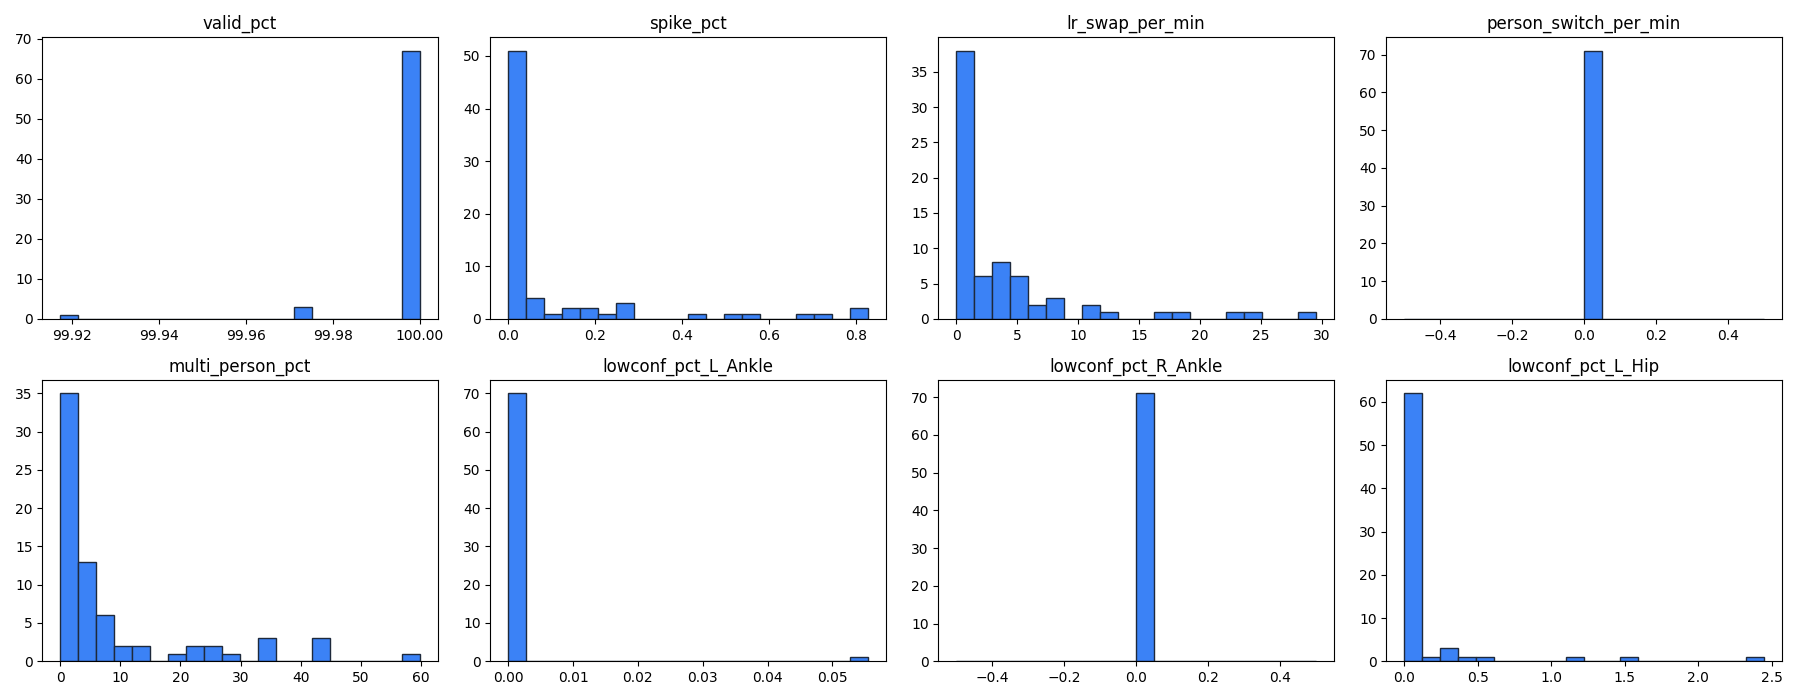

47 klip dibuat untuk 30 trial (sampel: ['PDFE02_1', 'PDFE29_1', 'PDFE18_1', 'PDFE31_3', 'PDFE26_3', 'PDFE09_1']).
Lembar cek manual: /kaggle/working/mobilefog_dwpose_patientlock/03_qc/qc_manual_review.csv (baru)
Plot & klip di-zip: /kaggle/working/mobilefog_dwpose_patientlock/03_qc/signals.zip, /kaggle/working/mobilefog_dwpose_patientlock/03_qc/clips.zip | total file output: 381


In [14]:
# ==============================================================================
# QC: METRIK PER TRIAL, PLOT SINYAL, KLIP OVERLAY, LEMBAR CEK MANUAL
# ==============================================================================
from IPython.display import Image, display

QC_DIR.mkdir(parents=True, exist_ok=True)
qc_rows, qc_cache = [], {}
for r in df_manifest.itertuples():
    z = np.load(RAW_POSE_DIR / r.split / f"{r.trial_id}.npz")
    lbl30 = pd.read_csv(r.label30_path)
    inside = lbl30["inside_imu_mask"].to_numpy() == 1
    y30 = lbl30["y_fog"].to_numpy()
    n_video = int(cv2.VideoCapture(r.video_path).get(cv2.CAP_PROP_FRAME_COUNT))
    n_persons = z["n_persons"] if "n_persons" in z.files else None
    row = qc_trial(z["kps"], z["valid"], z["boxes"], n_persons, float(z["fps"]), LB6_INDICES,
                   n_label30=len(lbl30), n_video=n_video, info_joints=joint_schema["feet_indices"])
    row = {"split": r.split, "trial_id": r.trial_id,
           "fog_pct": 100.0 * float(y30[inside].mean()) if inside.any() else 0.0, **row}
    qc_rows.append(row)
    ev = event_frames(z["kps"], z["valid"], z["boxes"], LB6_INDICES)
    qc_cache[r.trial_id] = (r, ev)
    plot_signals(z["kps"], z["valid"], y30, ev, LB6_INDICES,
                 f"{r.trial_id} [{r.split}] flags={row['flags'] or 'OK'}", QC_DIR / "signals" / f"{r.trial_id}.png")

df_qc = pd.DataFrame(qc_rows)
df_qc.to_csv(QC_DIR / "qc_per_trial.csv", index=False)
flagged = df_qc[df_qc["flags"] != ""]
print(f"QC selesai: {len(df_qc)} trial, {len(flagged)} ter-flag. Tabel: {QC_DIR / 'qc_per_trial.csv'}")
display(flagged[["split", "trial_id", "fog_pct", "flags", "valid_pct", "spike_pct", "lr_swap_per_min",
                 "person_switch_per_min", "multi_person_pct"]])
display(df_qc.describe().T)

import matplotlib.pyplot as plt
metrics = ["valid_pct", "spike_pct", "lr_swap_per_min", "person_switch_per_min", "multi_person_pct",
           "lowconf_pct_L_Ankle", "lowconf_pct_R_Ankle", "lowconf_pct_L_Hip"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7), dpi=100)
for ax, m in zip(axes.ravel(), metrics):
    ax.hist(df_qc[m].dropna(), bins=20, color="#3b82f6", edgecolor="#1e293b")
    ax.set_title(m)
fig.tight_layout()
fig.savefig(QC_DIR / "qc_histograms.png")
plt.close(fig)
display(Image(filename=str(QC_DIR / "qc_histograms.png")))

# Klip overlay 15 detik: semua trial ter-flag + 6 sampel train/val (seed 42)
sample_ids = pick_sample_trials(df_qc[["trial_id", "split", "fog_pct"]], seed=42)
clip_ids = sorted(set(flagged["trial_id"]) | set(sample_ids))
review_rows = []
for tid in clip_ids:
    r, ev = qc_cache[tid]
    z = np.load(RAW_POSE_DIR / r.split / f"{tid}.npz")
    y30 = pd.read_csv(r.label30_path)["y_fog"].to_numpy()
    fps = float(z["fps"])
    for s in clip_windows(len(z["valid"]), fps, y30, ev, seed=42):
        out = QC_DIR / "clips" / f"{tid}_{int(s / fps)}s.mp4"
        render_clip(r.video_path, z["kps"], z["boxes"], z["valid"], y30, s, int(round(15 * fps)), out, LB6_INDICES)
        review_rows.append((tid, out.name))
created = write_review_template(QC_DIR / "qc_manual_review.csv", review_rows)
print(f"{len(review_rows)} klip dibuat untuk {len(clip_ids)} trial (sampel: {sample_ids}).")
print("Lembar cek manual:", QC_DIR / "qc_manual_review.csv", "(baru)" if created else "(sudah ada, tidak ditimpa)")

# Kaggle membatasi jumlah file output (~500): gabungkan plot & klip ke zip
for sub in ("signals", "clips"):
    if (QC_DIR / sub).exists():
        shutil.make_archive(str(QC_DIR / sub), "zip", root_dir=QC_DIR / sub)
        shutil.rmtree(QC_DIR / sub)
n_out_files = sum(1 for p in OUTPUT_ROOT.rglob("*") if p.is_file())
print(f"Plot & klip di-zip: {QC_DIR / 'signals.zip'}, {QC_DIR / 'clips.zip'} | total file output: {n_out_files}")

## Langkah berikutnya
1. **Simpan output**: jalankan *Save Version → Save & Run All* agar `/kaggle/working/mobilefog_dwpose_patientlock` tersimpan, lalu jadikan output ini Kaggle Dataset untuk notebook training.
2. **Cek manual QC**: unduh `03_qc/clips.zip`, `03_qc/signals.zip`, `03_qc/qc_per_trial.csv`, dan `03_qc/qc_manual_review.csv`. Tonton klip, isi CSV, lalu simpan CSV yang sudah diisi ke repo (`qc/qc_manual_review.csv`). Klip tidak di-commit.
3. **Training**: di notebook training 4 model tim, isi `DATA_DIR` ke folder `mobilefog_dwpose_patientlock` (auto-detect di sana mengambil folder `D_windowed_stgcn_cls` pertama yang ditemukan, jadi isi manual bila ada lebih dari satu dataset di Input).